# Handwritten Digit Classification Using an Artificial Neural Network (ANN)

**Practical:** MNIST digit classification (0–9) using a fully connected neural network.

## Aim
Develop, train, and evaluate an ANN that classifies 28 × 28 grayscale images of handwritten digits into ten classes.

## Objectives
1. Load and inspect the MNIST dataset.
2. Normalize pixel values and prepare training, validation, and test sets.
3. Build an ANN with an input layer, hidden layers, and a 10-neuron softmax output layer.
4. Train with cross-entropy loss and the Adam optimizer.
5. Evaluate accuracy, precision, recall, and the confusion matrix.
6. Compare a few hyperparameter configurations and discuss results against indicative published reference points.

## Environment
This notebook uses TensorFlow/Keras, NumPy, Matplotlib, Pandas, and scikit-learn. It can run in Google Colab or Kaggle. For a local environment, use a TensorFlow-supported Python version and install the dependencies if needed:

```bash
pip install tensorflow numpy matplotlib pandas scikit-learn
```

The MNIST dataset is loaded from `tf.keras.datasets.mnist`; a separate manual download is not required. The standard split contains 60,000 training images and 10,000 test images.

## 1. Background and methodology

Each MNIST image is a 28 × 28 grayscale array, so a fully connected ANN receives **784 input features** after flattening. Pixel values are scaled from the original range 0–255 to 0–1. The hidden layers use ReLU activations, and the output layer has ten softmax units—one for each digit.

For a true class label \(y\), sparse categorical cross-entropy is

\[
L = -\log(p_y),
\]

where \(p_y\) is the model's predicted probability for the correct class. Adam updates the weights using gradients of this loss. The original integer labels (0–9) are retained, so **sparse** categorical cross-entropy is appropriate; one-hot encoding is not required.

**Evaluation discipline:** the official test set is held out until final evaluation. Hyperparameter experiments below use validation accuracy, not test accuracy, to reduce test-set leakage.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Num GPUs available:", len(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
Num GPUs available: 0


## 2. Load the MNIST dataset and inspect its structure

In [2]:
(X_train_raw, y_train_raw), (X_test_raw, y_test) = tf.keras.datasets.mnist.load_data()

print("Training image shape:", X_train_raw.shape)
print("Training label shape:", y_train_raw.shape)
print("Test image shape:    ", X_test_raw.shape)
print("Test label shape:    ", y_test.shape)
print("Pixel data type:", X_train_raw.dtype)
print("Raw pixel range:", X_train_raw.min(), "to", X_train_raw.max())
print("Classes:", np.unique(y_train_raw))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Training image shape: (60000, 28, 28)
Training label shape: (60000,)
Test image shape:     (10000, 28, 28)
Test label shape:     (10000,)
Pixel data type: uint8
Raw pixel range: 0 to 255
Classes: [0 1 2 3 4 5 6 7 8 9]


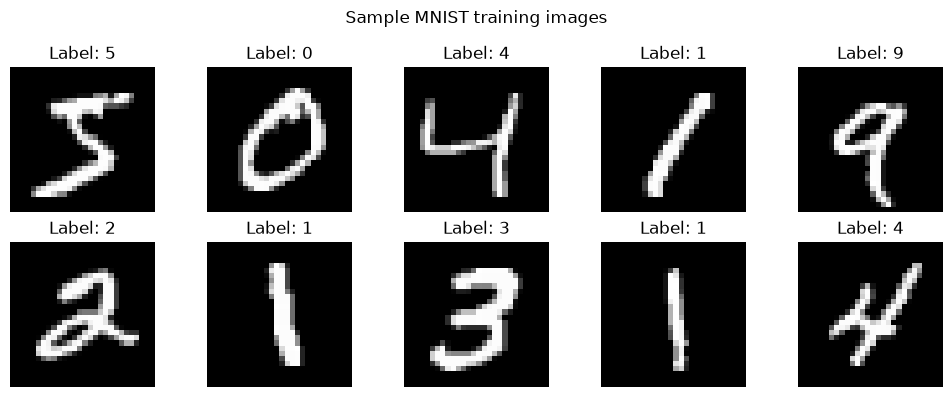

In [3]:
# Show a sample of the images and their labels.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_raw[i], cmap="gray")
    ax.set_title(f"Label: {y_train_raw[i]}")
    ax.axis("off")
plt.suptitle("Sample MNIST training images")
plt.tight_layout()
plt.show()

,Training examples
Digit,
0,5923
1,6742
2,5958
3,6131
4,5842
5,5421
6,5918
7,6265
8,5851


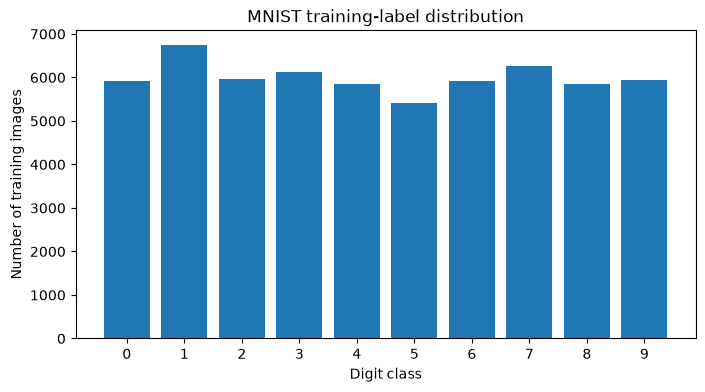

In [4]:
# Inspect the number of examples for each digit.
class_counts = pd.Series(y_train_raw).value_counts().sort_index()
display(class_counts.rename_axis("Digit").to_frame("Training examples"))

plt.figure(figsize=(8, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Digit class")
plt.ylabel("Number of training images")
plt.title("MNIST training-label distribution")
plt.show()

## 3. Preprocess the images and create a validation split

- **Normalize:** divide each pixel by 255 to convert it to a floating-point value in [0, 1].
- **Flatten:** convert each 28 × 28 image into a vector containing 784 values because Dense layers operate on vectors.
- **Split:** use 90% of the original training set for fitting and 10% for validation. The official 10,000-image test set remains untouched until final evaluation.

The labels are integers from 0 to 9.

In [5]:
# Normalize pixels and flatten 28 x 28 images into 784-element vectors.
X_train_all = X_train_raw.astype("float32").reshape(-1, 28 * 28) / 255.0
X_test = X_test_raw.astype("float32").reshape(-1, 28 * 28) / 255.0

y_train_all = y_train_raw.astype("int64")
y_test = y_test.astype("int64")

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all,
    y_train_all,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_all,
)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)
print("Normalized pixel range:", float(X_train.min()), "to", float(X_train.max()))

X_train: (54000, 784) y_train: (54000,)
X_val:   (6000, 784) y_val:   (6000,)
X_test:  (10000, 784) y_test:  (10000,)
Normalized pixel range: 0.0 to 1.0


## 4. Build the ANN

Architecture used for the main experiment:

- Input: 784 pixel features
- Hidden layer 1: 256 neurons, ReLU
- Dropout: 20% during training to help reduce overfitting
- Hidden layer 2: 128 neurons, ReLU
- Dropout: 20%
- Output: 10 neurons, softmax (probabilities for digits 0–9)

In [6]:
def build_ann(hidden_units=(256, 128), learning_rate=0.001, dropout_rate=0.20):
    """Create a feed-forward ANN for 10-class MNIST classification."""
    layers = [tf.keras.layers.Input(shape=(784,))]

    for units in hidden_units:
        layers.append(tf.keras.layers.Dense(units, activation="relu"))
        if dropout_rate > 0:
            layers.append(tf.keras.layers.Dropout(dropout_rate))

    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    model = tf.keras.Sequential(layers, name="MNIST_ANN")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_ann()
model.summary()

Model: "MNIST_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the ANN

Early stopping restores the weights from the best validation-loss epoch. The learning-rate scheduler lowers the learning rate if validation loss stops improving. The number of epochs below is a maximum; early stopping may finish training sooner.

In [7]:
EPOCHS = 10
BATCH_SIZE = 128

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1
    ),
]

start_time = time.perf_counter()
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)
main_training_seconds = time.perf_counter() - start_time
print(f"Training time: {main_training_seconds:.2f} seconds")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8946 - loss: 0.3508 - val_accuracy: 0.9545 - val_loss: 0.1514 - learning_rate: 0.0010
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9571 - loss: 0.1451 - val_accuracy: 0.9668 - val_loss: 0.1105 - learning_rate: 0.0010
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9677 - loss: 0.1059 - val_accuracy: 0.9728 - val_loss: 0.1001 - learning_rate: 0.0010
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9741 - loss: 0.0843 - val_accuracy: 0.9743 - val_loss: 0.0830 - learning_rate: 0.0010
Epoch 5/10
417/422 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9792 - loss: 0.0683
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9791 - loss: 0.0684 - val_accuracy: 0.9757 - val_loss: 0.0874 - learning_rate: 0.0010
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9843 - loss: 0.0505 - v

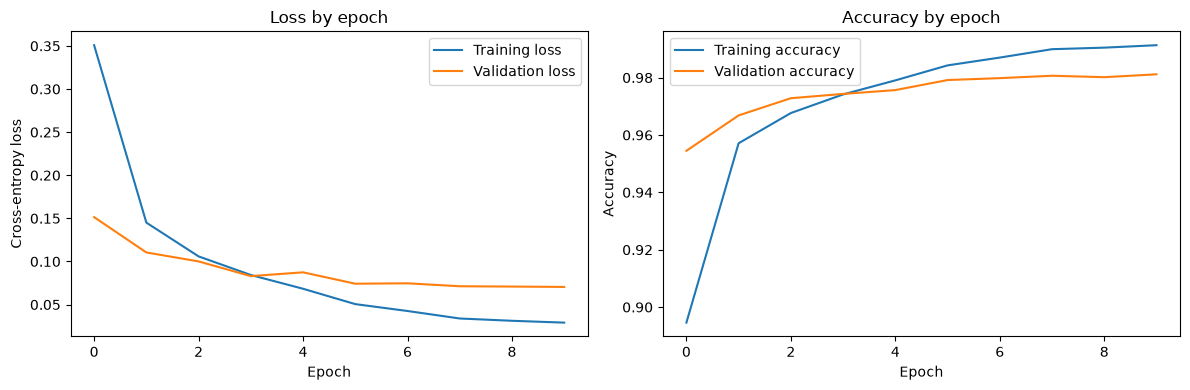

In [8]:
# Plot learning curves to see how loss and accuracy changed during training.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Loss by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Final evaluation on the held-out test set

Accuracy is the fraction of correct predictions. Precision measures how often predictions for a class are correct; recall measures how many examples of a class are found. Macro averages treat all ten classes equally, while weighted averages account for the number of test examples in each class.

In [9]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
probabilities = model.predict(X_test, batch_size=256, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

metrics_summary = pd.DataFrame(
    {
        "Metric": ["Test loss", "Accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted precision", "Weighted recall", "Weighted F1"],
        "Score": [
            test_loss,
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred, average="macro", zero_division=0),
            recall_score(y_test, y_pred, average="macro", zero_division=0),
            f1_score(y_test, y_pred, average="macro", zero_division=0),
            precision_score(y_test, y_pred, average="weighted", zero_division=0),
            recall_score(y_test, y_pred, average="weighted", zero_division=0),
            f1_score(y_test, y_pred, average="weighted", zero_division=0),
        ],
    }
)
display(metrics_summary.style.format({"Score": "{:.4f}"}))
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

,Metric,Score
0,Test loss,0.0564
1,Accuracy,0.9825
2,Macro precision,0.9824
3,Macro recall,0.9824
4,Macro F1,0.9824
5,Weighted precision,0.9825
6,Weighted recall,0.9825
7,Weighted F1,0.9825


Test accuracy: 98.25%


In [10]:
# Precision, recall, F1-score, and support for each digit class.
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

              precision    recall  f1-score   support

           0     0.9828    0.9898    0.9863       980
           1     0.9895    0.9930    0.9912      1135
           2     0.9873    0.9777    0.9825      1032
           3     0.9783    0.9812    0.9797      1010
           4     0.9847    0.9837    0.9842       982
           5     0.9820    0.9809    0.9815       892
           6     0.9823    0.9843    0.9833       958
           7     0.9759    0.9854    0.9806      1028
           8     0.9803    0.9713    0.9758       974
           9     0.9811    0.9762    0.9786      1009

    accuracy                         0.9825     10000
   macro avg     0.9824    0.9824    0.9824     10000
weighted avg     0.9825    0.9825    0.9825     10000



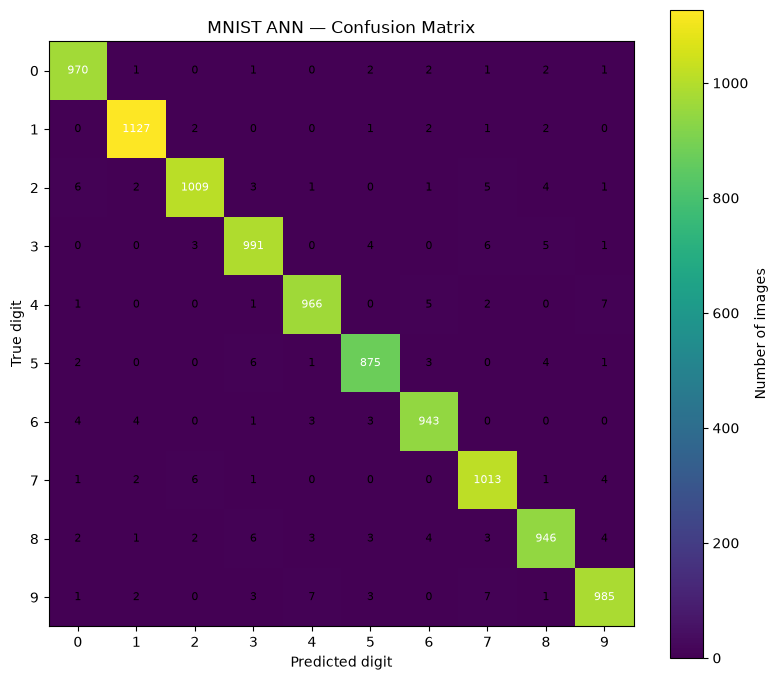

In [11]:
# Confusion matrix: rows are true labels and columns are predicted labels.
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
plt.figure(figsize=(8, 7))
plt.imshow(cm, interpolation="nearest")
plt.title("MNIST ANN — Confusion Matrix")
plt.colorbar(label="Number of images")
plt.xticks(np.arange(10), np.arange(10))
plt.yticks(np.arange(10), np.arange(10))
plt.xlabel("Predicted digit")
plt.ylabel("True digit")

threshold = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                 color="white" if cm[i, j] > threshold else "black", fontsize=8)
plt.tight_layout()
plt.show()

Misclassified images: 175 out of 10000


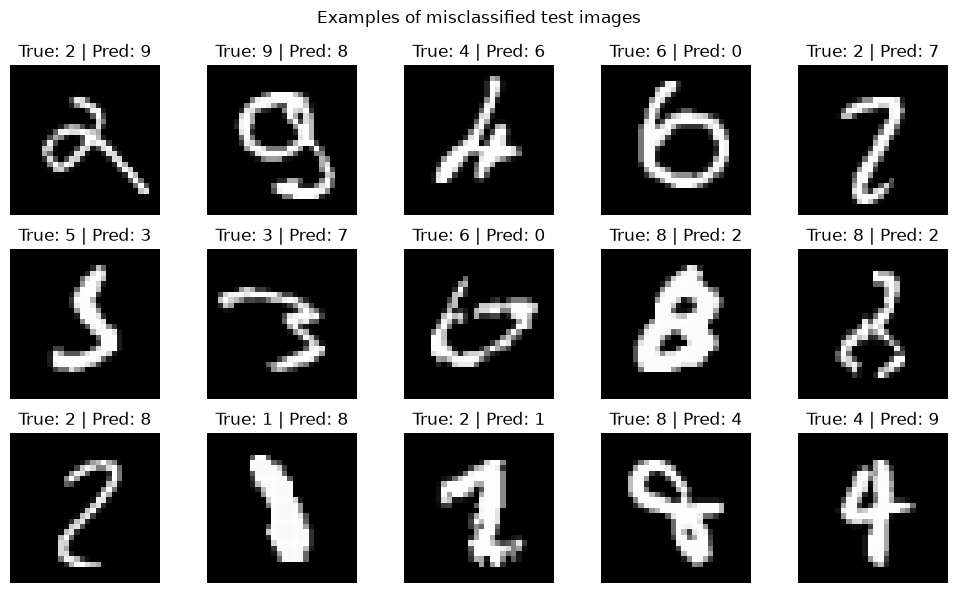

In [12]:
# Inspect some errors to understand which handwriting patterns confuse the ANN.
misclassified = np.flatnonzero(y_pred != y_test)
print(f"Misclassified images: {len(misclassified)} out of {len(y_test)}")

n_show = min(15, len(misclassified))
fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, idx in zip(axes.flat, misclassified[:n_show]):
    ax.imshow(X_test_raw[idx], cmap="gray")
    ax.set_title(f"True: {y_test[idx]} | Pred: {y_pred[idx]}")
    ax.axis("off")
plt.suptitle("Examples of misclassified test images")
plt.tight_layout()
plt.show()

## 7. Hyperparameter impact analysis

To keep this experiment reasonably quick, four configurations are trained for four epochs each. They use the same training/validation partition and differ from the baseline in **one main setting at a time**. The test set is not used for these comparisons.

- **Hidden-layer width:** changes the number of neurons while keeping the number of layers fixed.
- **Batch size:** smaller batches make more parameter updates per epoch but may be noisier.
- **Learning rate:** a higher value may learn faster but can overshoot good solutions or make training unstable.

The experiment is illustrative, not an exhaustive hyperparameter search. Because random initialization and short training affect results, use the measured validation scores from your own run in the lab discussion.

In [13]:
def run_hyperparameter_experiment(name, hidden_units=(128, 64), learning_rate=0.001,
                                  batch_size=128, epochs=4, dropout_rate=0.0):
    """Train one comparison model and report validation metrics and training time."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    exp_model = build_ann(
        hidden_units=hidden_units,
        learning_rate=learning_rate,
        dropout_rate=dropout_rate,
    )
    start = time.perf_counter()
    exp_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0,
    )
    elapsed = time.perf_counter() - start
    val_loss, val_accuracy = exp_model.evaluate(X_val, y_val, verbose=0)
    return {
        "Configuration": name,
        "Hidden units": str(list(hidden_units)),
        "Learning rate": learning_rate,
        "Batch size": batch_size,
        "Epochs": epochs,
        "Validation accuracy": val_accuracy,
        "Validation loss": val_loss,
        "Training time (s)": elapsed,
    }

experiment_configs = [
    {"name": "Baseline", "hidden_units": (128, 64), "learning_rate": 0.001, "batch_size": 128},
    {"name": "Wider hidden layers", "hidden_units": (256, 128), "learning_rate": 0.001, "batch_size": 128},
    {"name": "Smaller batch", "hidden_units": (128, 64), "learning_rate": 0.001, "batch_size": 64},
    {"name": "Higher learning rate", "hidden_units": (128, 64), "learning_rate": 0.01, "batch_size": 128},
]

RUN_HYPERPARAMETER_EXPERIMENTS = True

if RUN_HYPERPARAMETER_EXPERIMENTS:
    experiment_rows = []
    for cfg in experiment_configs:
        row = run_hyperparameter_experiment(
            name=cfg["name"],
            hidden_units=cfg["hidden_units"],
            learning_rate=cfg["learning_rate"],
            batch_size=cfg["batch_size"],
            epochs=4,
            dropout_rate=0.0,
        )
        experiment_rows.append(row)
        print(f"Finished: {cfg['name']}")

    hyperparameter_results = pd.DataFrame(experiment_rows)
    display(hyperparameter_results.style.format({
        "Learning rate": "{:.4g}",
        "Validation accuracy": "{:.4f}",
        "Validation loss": "{:.4f}",
        "Training time (s)": "{:.2f}",
    }))
else:
    print("Hyperparameter experiments skipped. Set RUN_HYPERPARAMETER_EXPERIMENTS = True to run them.")


Finished: Baseline
Finished: Wider hidden layers
Finished: Smaller batch
Finished: Higher learning rate


,Configuration,Hidden units,Learning rate,Batch size,Epochs,Validation accuracy,Validation loss,Training time (s)
0,Baseline,"[128, 64]",0.001,128,4,0.9692,0.1138,5.69
1,Wider hidden layers,"[256, 128]",0.001,128,4,0.9743,0.0938,5.98
2,Smaller batch,"[128, 64]",0.001,64,4,0.9700,0.1083,6.91
3,Higher learning rate,"[128, 64]",0.01,128,4,0.9637,0.1536,4.50


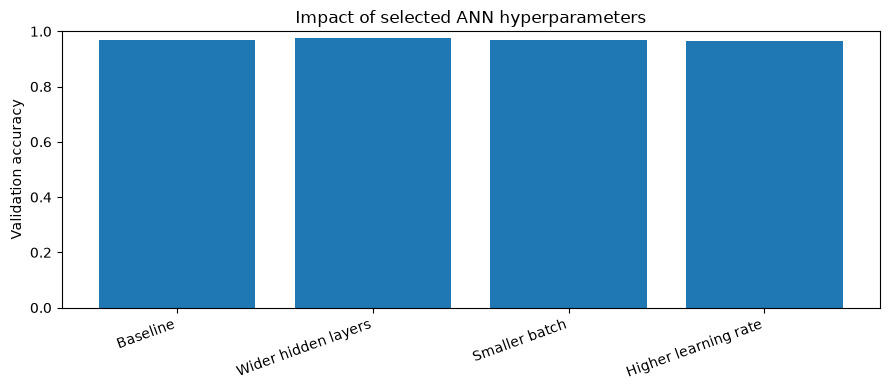

Best validation configuration in this run: Wider hidden layers (validation accuracy = 0.9743).


In [14]:
if RUN_HYPERPARAMETER_EXPERIMENTS:
    plt.figure(figsize=(9, 4))
    plt.bar(hyperparameter_results["Configuration"], hyperparameter_results["Validation accuracy"])
    plt.ylabel("Validation accuracy")
    plt.title("Impact of selected ANN hyperparameters")
    plt.ylim(0, 1)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

    best_row = hyperparameter_results.loc[hyperparameter_results["Validation accuracy"].idxmax()]
    print(
        f"Best validation configuration in this run: {best_row['Configuration']} "
        f"(validation accuracy = {best_row['Validation accuracy']:.4f})."
    )

## 8. Comparison with common MNIST reference points

Published results depend on preprocessing, architecture, data split, training schedule, and model selection, so they should be treated as context rather than a guaranteed target.

| Model family | Indicative test accuracy | Interpretation |
|---|---:|---|
| Fully connected MLP / dense ANN | Roughly 97–98.5% in common implementations | Appropriate comparison for this practical; performance depends on architecture and tuning. |
| CNN | Around 99% or higher in many standard examples | Usually stronger because convolution layers exploit local spatial patterns; **not a like-for-like comparison** with a dense ANN. |

References:
- A documented multilayer perceptron experiment reports **98.33%** test accuracy: [Technical Report: Multilayer Perceptron on MNIST](https://cocalc.com/share/download/32b94ee413d02759d719862907bb0a85a76c43f1/2016-11-07-175929.pdf).
- The official Keras example describes a simple CNN achieving approximately **99%** test accuracy: [Keras — Simple MNIST convnet](https://keras.io/examples/vision/mnist_convnet/).

Use the metric actually printed by this notebook in your report. Do not claim a result before running the notebook, and do not compare a validation score directly to a published test score as if the protocols were identical.

## 9. Optional: save the trained ANN

Run this cell if you need to save the final model for a demonstration or later inference.

In [15]:
# Uncomment to save the trained model in the current notebook directory.
# model.save("mnist_ann.keras")
# print("Saved model to mnist_ann.keras")

## 10. Result and conclusion (complete after running)

After executing all cells, record the actual results produced by your run.

- **Test accuracy:** use the value printed in Section 6.
- **Precision and recall:** report macro and/or weighted averages, and explain that precision measures correctness of predicted positives for each class while recall measures how many true examples of each class were found.
- **Confusion matrix:** identify digit pairs that are most often confused. Look at the misclassified examples to suggest why their shapes may be similar.
- **Hyperparameters:** compare validation accuracy and training time in Section 7. Discuss whether wider layers, batch size, or learning rate helped in this run; note that more neurons can increase computation and overfitting risk, while learning rate and batch size influence optimization behaviour.
- **Benchmark:** explain whether your dense ANN is in the expected MLP range, while noting that CNN results are typically higher and use a different architecture.

**Conclusion template:** “A fully connected ANN was trained on normalized MNIST images using Adam and sparse categorical cross-entropy. The model achieved **[insert measured test accuracy]** test accuracy. Macro precision was **[value]** and macro recall was **[value]**. The hyperparameter experiment showed **[insert observation from your table]**. The results are consistent with the expectation that an MLP performs strongly on MNIST, although CNNs can usually exploit image structure more effectively.”